# Cloud Workload Forecasting and Analysis
## Atomity Azure data-v1 review notebook
This notebook executes the same tested package used by the prediction CLI. Open the project folder in VS Code, select the project's `.venv` kernel, and choose **Run All**. Install with `python -m pip install -e '.[dev,notebook,report]'`.

**Protocol:** first 110 timestamps for fitting and internal validation; final 24 timestamps for forecasts only. Full-window structural auditing is allowed, but holdout CPU labels are never displayed, scored, or used for model selection. Timestamps are trace-relative seconds, not Unix dates.

The objective is to establish predictability, measure two-hour forecast accuracy, and propose defensible infrastructure actions, not maximize model complexity.

In [1]:
from pathlib import Path
import contextlib
import io
import json
import os
import platform
import subprocess
import sys
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
def show_table(frame):
    styled = frame.style.format(precision=5, na_rep='N/A').set_properties(**{'color': '#17212b !important', 'background-color': '#ffffff !important', 'padding': '6px 10px', 'border': '1px solid #d0d7de'})
    styled = styled.set_table_styles([{'selector': 'table', 'props': [('color', '#17212b !important'), ('background-color', '#ffffff !important'), ('border-collapse', 'collapse')]}, {'selector': 'th', 'props': [('color', '#17212b !important'), ('background-color', '#e8eef3 !important'), ('padding', '6px 10px')]}])
    display(styled)
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists() and (p / 'src/atomity_forecasting').exists()), None)
assert ROOT is not None, 'Open this notebook inside the project folder'
os.chdir(ROOT)
DATA = ROOT / 'challenge_data'
REPORTS = ROOT / 'reports'
RESULTS = REPORTS / 'results'
FIGURES = REPORTS / 'figures'
print('Project:', ROOT.name)
print('Python:', platform.python_version(), '| NumPy:', np.__version__, '| pandas:', pd.__version__)
print('Forecast setting: 110 training timestamps, 24 forecast steps, 300-second cadence')
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from typing import Any
from atomity_forecasting.models import TARGETS
from atomity_forecasting.plotting import save_figure

Project: TASK
Python: 3.13.9 | NumPy: 2.5.4 | pandas: 3.0.6
Forecast setting: 110 training timestamps, 24 forecast steps, 300-second cadence


## 1. Ingestion, Target Definitions, and Model Freeze
Use only the released CPU and metadata files; verify the bundled manifest before reading. Valid observations require a VM ID and finite `0 <= min_cpu <= avg_cpu <= max_cpu <= 100`. Average valid duplicates within each VM/timestamp before averaging across VMs; count a VM once. Invalid records produce warnings and audit counts. Missing whole timestamps fail explicitly; no silent imputation.

Construct the full targets as required, then pass only the first 110 labels to selection. The cells below deliberately do not display the full target table. Models use past targets only; source metadata utilization summaries are not predictive features.

In [2]:
from atomity_forecasting.data import load_data, construct_targets
from atomity_forecasting.predict import forecast_targets
cpu, metadata, audit = load_data(DATA)
targets = construct_targets(cpu)
predictions, selection, backtests = forecast_targets(targets, train_size=110, horizon=24)
frozen_selection = json.dumps(selection, sort_keys=True)
train = targets.iloc[:110].copy()
forecast_timestamps = targets.timestamp.iloc[110:134].copy()
del targets, cpu, metadata
print('Checksums verified:', len(audit['checksums']))
show_table(pd.DataFrame([{'target': target, 'selected_model': item['model'], 'best_baseline': item['best_baseline']} for target, item in selection['targets'].items()]))
print('Selection is frozen before descriptive plots. No holdout scores are computed.')

Checksums verified: 3


,target,selected_model,best_baseline
0,active_vm_count,persistence,persistence
1,aggregate_cpu_utilization,persistence,persistence


Selection is frozen before descriptive plots. No holdout scores are computed.


## 2. Time-Aware Validation
Seven fixed candidates: persistence, trailing means over 6/12/24 observations, SES alpha 0.2/0.5, and damped Holt with fixed alpha/beta/damping 0.3/0.1/0.9. There is no numerical hyperparameter optimization.

Origins are fitting-prefix lengths 50, 70, and 86; each predicts 24 steps without observing intermediate actuals. All outcomes remain within the first 110 timestamps. Selection minimizes pooled MAE, with candidate-order tie-breaking favoring persistence. There are 72 errors per candidate/target but only 60 distinct validation timestamps; overlapping errors are not independent.

Relative improvement uses the best simple baseline's MAE, not pointwise percentage errors. A zero baseline error produces an undefined improvement, not division by zero.

In [3]:
from atomity_forecasting.analysis import main as run_analysis
from atomity_forecasting.plotting import PLOTTERS
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython import get_ipython
with contextlib.redirect_stdout(io.StringIO()):
    computed = run_analysis(['--data', str(DATA), '--output', str(REPORTS)], render_figures=False)
tables = computed['tables']
summaries = computed['summaries']
get_ipython().run_line_magic('matplotlib', 'inline')
assert set(computed['plot_inputs']) == set(PLOTTERS)
summary = summaries['analysis_summary']
full_audit = summaries['audit']
assert json.dumps(summary['selection'], sort_keys=True) == frozen_selection
assert summary['scope']['holdout_scored'] is False
print('Calculated tables and all 12 figures directly from the raw release.')

Calculated tables and all 12 figures directly from the raw release.


## 3. Data Quality, Lifetimes, and Churn
**Observation -> explanation -> implication:** Complete-trace curation produces constant observed coverage and no entries/exits. This makes count forecasting trivial for this sample, not proof that real fleet churn is predictable. Metadata lifetimes extend beyond the observation window and are descriptive only. Category/core stratification and survival through the complete window limit generalization.

In [4]:
show_table(tables['data_quality'])
show_table(tables['missingness'])
show_table(tables['observations_per_vm'])
show_table(pd.DataFrame([full_audit['coverage']]))
show_table(pd.DataFrame([full_audit['lifetimes']['lifetime_seconds']]))
show_table(tables['metadata_cpu_statistics'])

,metric,count
0,raw_rows,1340000
1,clean_rows,1340000
2,duplicate_key_rows,0
3,invalid_cpu_or_id_rows,0
4,invalid_cpu_range_rows,0
5,invalid_min_mean_max_rows,0
6,vms_missing_metadata,0
7,metadata_without_readings,0


,table,column,missing_rows,total_rows
0,cpu_raw,timestamp,0,1340000
1,cpu_raw,vm_id,0,1340000
2,cpu_raw,min_cpu,0,1340000
3,cpu_raw,max_cpu,0,1340000
4,cpu_raw,avg_cpu,0,1340000
5,metadata,vm_id,0,10000
6,metadata,subscription_id,0,10000
7,metadata,deployment_id,0,10000
8,metadata,timestamp_vm_created,0,10000
9,metadata,timestamp_vm_deleted,0,10000


,observations,vm_count
0,134,10000


,min_vm_count,max_vm_count,total_entries_after_first,total_exits_after_first
0,10000,10000,0.00000,0.00000


,n,min,max,mean,median,std_ddof1,p10,p25,p75,p90,p95,p99
0,10000,40500.00000,2591400.00000,2289625.62000,2591400.00000,708100.83404,755760.00000,2591400.00000,2591400.00000,2591400.00000,2591400.00000,2591400.00000


,column,n,min,max,mean,median,std_ddof1,p10,p25,p75,p90,p95,p99,fraction_gt100,fraction_negative,non_numeric_or_missing
0,max_cpu,10000,0.02888,100.00000,86.49223,95.42356,18.76032,59.88909,82.29958,98.38192,99.13207,99.30436,99.43962,0.00000,0.00000,0
1,avg_cpu,10000,0.00806,99.19946,9.33825,5.85904,11.25350,1.52725,3.04647,10.53240,20.08235,30.77112,57.03689,0.00000,0.00000,0
2,p95_max_cpu,10000,0.02515,99.51912,36.36533,23.97579,29.43777,6.71671,10.59103,62.02933,80.37080,96.21048,98.78204,0.00000,0.00000,0


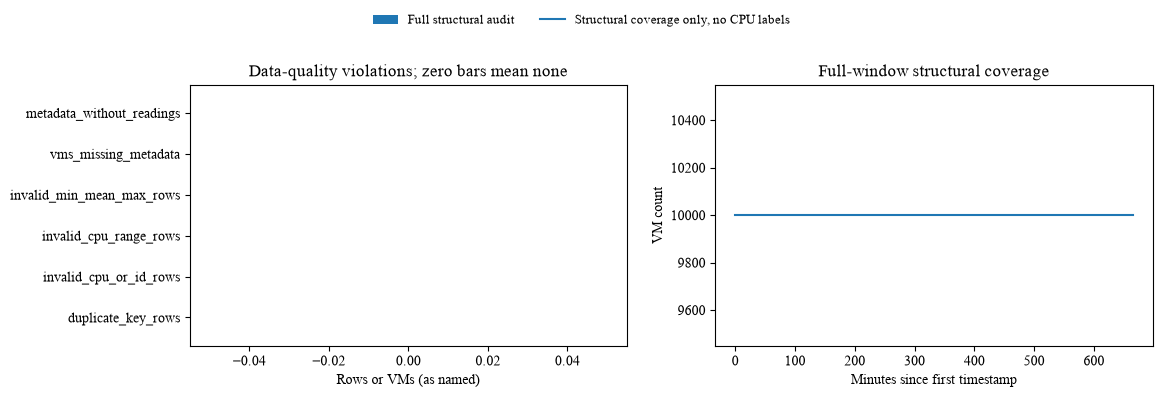

In [5]:
def plot_data_quality(issues: pd.Series, coverage: pd.DataFrame) -> Figure:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].barh(issues.index, issues, label="Full structural audit")
    axes[0].set(xlabel="Rows or VMs (as named)", title="Data-quality violations; zero bars mean none")
    axes[1].plot((coverage.timestamp - coverage.timestamp.iloc[0]) / 60, coverage.vm_count,
                 label="Structural coverage only, no CPU labels")
    axes[1].set(xlabel="Minutes since first timestamp", ylabel="VM count", title="Full-window structural coverage")
    return fig

fig = plot_data_quality(*computed['plot_inputs']['data_quality'])
save_figure(fig, FIGURES / 'data_quality.png')
computed['figures']['data_quality'] = fig
FigureCanvasAgg(fig)
display(fig)

## 4. Training Workload Analysis
Every chart is generated from data during this run, not loaded from a PNG. Each chart displays the exact Python function from [plotting.py](../src/atomity_forecasting/plotting.py) beside its live output. The analysis, notebook, and report use that single implementation; the code is not duplicated in notebook cells. PNGs are exports for the report.
**Observation -> explanation -> implication:** The equal-VM aggregate stays near 9.4% while the VM-level distribution has a high-utilization tail. Averaging heterogeneous VMs likely smooths bursts. Low mean utilization is therefore not sufficient evidence to downsize all VMs.

The training aggregate peaks at trace second 16,500 and is lowest at 32,400. Short-lag persistence is descriptive; an approximately eleven-hour release cannot establish daily or weekly seasonality. High readings are not automatically bad telemetry or confirmed service incidents, so valid extremes are retained.

In [6]:
show_table(pd.DataFrame([summary['training_aggregate']]).assign(scope='training aggregate CPU (%)'))
show_table(pd.DataFrame([{k: v for k, v in summary['training_cpu'].items() if k != 'vm_mean_distribution'}]))
show_table(pd.DataFrame([summary['volatility']]))

,n,min,max,mean,median,std_ddof1,p10,p25,p75,p90,p95,p99,scope
0,110,9.11163,9.91218,9.41409,9.37812,0.19357,9.17920,9.28895,9.50767,9.66836,9.82915,9.90491,training aggregate CPU (%)


,n,min,max,mean,median,std_ddof1,p10,p25,p75,p90,p95,p99,share_avg_ge80,share_avg_ge95
0,1100000,0.00716,99.48803,9.41409,5.11981,14.27521,1.23480,2.48695,9.64797,19.69112,37.29325,87.40635,0.01272,0.00566


,aggregate_std_pp,difference_std_pp,max_absolute_delta_pp,lag1_autocorrelation
0,0.19357,0.15803,0.43683,0.66724


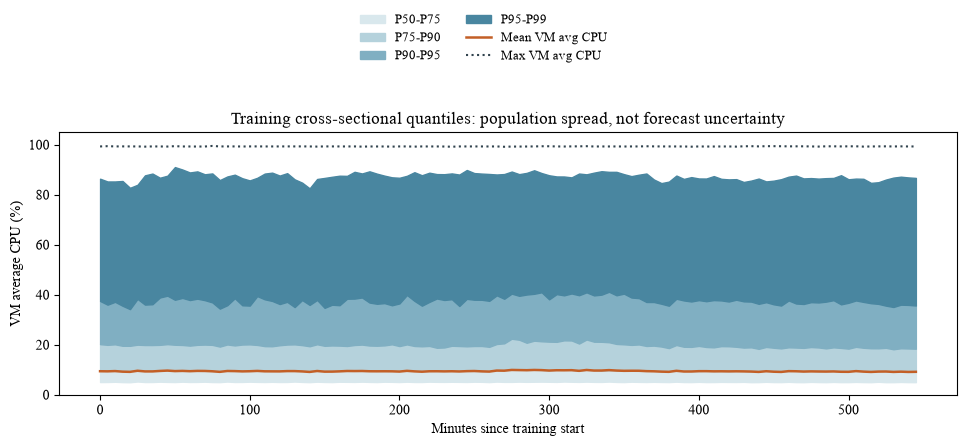

In [7]:
def plot_cross_sectional_fan(cross_section: pd.DataFrame) -> Figure:
    minutes = (cross_section.timestamp - cross_section.timestamp.iloc[0]) / 60
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bands = [("p50_avg_cpu", "p75_avg_cpu", "#d9e8ed", "P50-P75"),
             ("p75_avg_cpu", "p90_avg_cpu", "#b5d2dc", "P75-P90"),
             ("p90_avg_cpu", "p95_avg_cpu", "#80afc2", "P90-P95"),
             ("p95_avg_cpu", "p99_avg_cpu", "#4986a0", "P95-P99")]
    for lower, upper, color, label in bands:
        ax.fill_between(minutes, cross_section[lower], cross_section[upper], color=color, label=label)
    ax.plot(minutes, cross_section.mean_avg_cpu, color="#c35f26", label="Mean VM avg CPU", linewidth=1.8)
    ax.plot(minutes, cross_section.max_avg_cpu, color="#31434e", linestyle=":", label="Max VM avg CPU")
    ax.set(xlabel="Minutes since training start", ylabel="VM average CPU (%)", ylim=(0, 105),
           title="Training cross-sectional quantiles: population spread, not forecast uncertainty")
    return fig

fig = plot_cross_sectional_fan(*computed['plot_inputs']['cross_sectional_fan'])
save_figure(fig, FIGURES / 'cross_sectional_fan.png')
computed['figures']['cross_sectional_fan'] = fig
FigureCanvasAgg(fig)
display(fig)

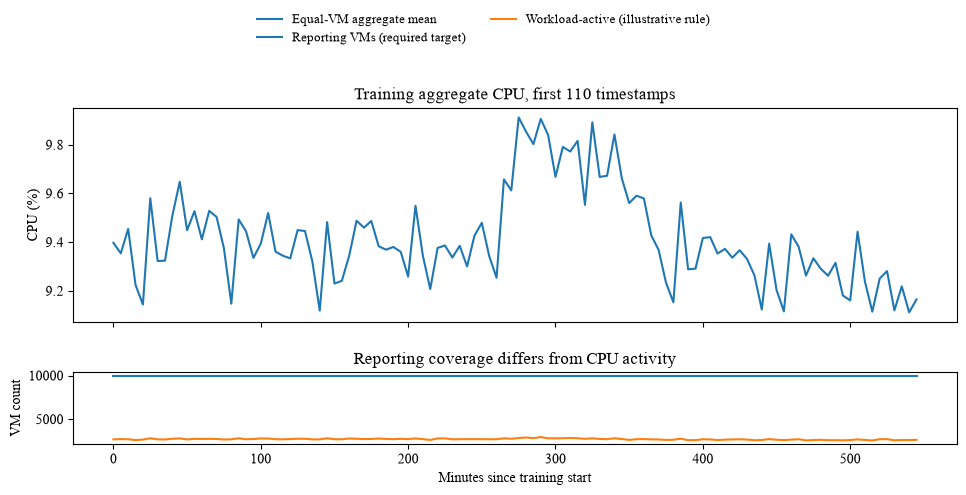

In [8]:
def plot_training_cpu_coverage(per_time: pd.DataFrame, cross_section: pd.DataFrame) -> Figure:
    minutes = (per_time.timestamp - per_time.timestamp.iloc[0]) / 60
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1]})
    axes[0].plot(minutes, per_time.aggregate_cpu_utilization, label="Equal-VM aggregate mean")
    axes[0].set(ylabel="CPU (%)", title="Training aggregate CPU, first 110 timestamps")
    axes[1].plot(minutes, per_time.active_vm_count, label="Reporting VMs (required target)")
    axes[1].plot(minutes, cross_section.workload_active_vm_count, label="Workload-active (illustrative rule)")
    axes[1].set(ylabel="VM count", xlabel="Minutes since training start", title="Reporting coverage differs from CPU activity")
    return fig

fig = plot_training_cpu_coverage(*computed['plot_inputs']['training_cpu_coverage'])
save_figure(fig, FIGURES / 'training_cpu_coverage.png')
computed['figures']['training_cpu_coverage'] = fig
FigureCanvasAgg(fig)
display(fig)

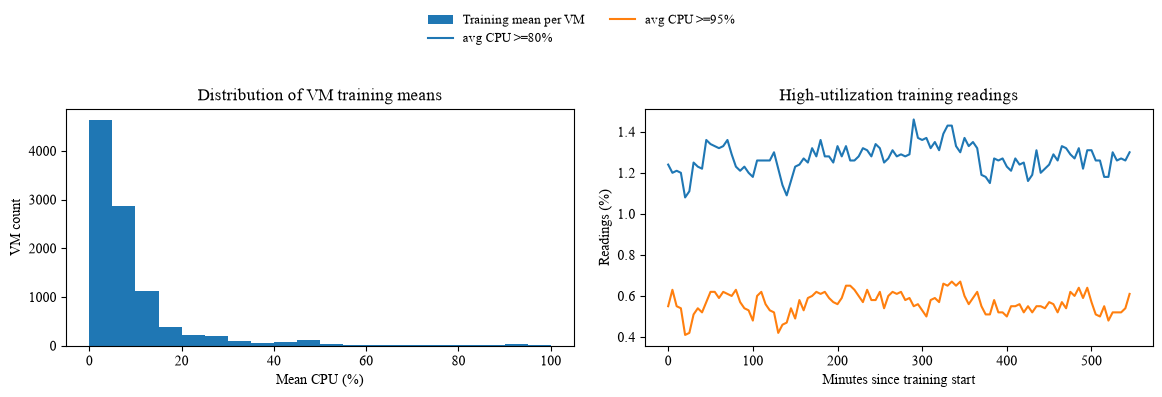

In [9]:
def plot_vm_utilization(vm_means: pd.Series, bins: np.ndarray, time_summary: pd.DataFrame) -> Figure:
    minutes = (time_summary.timestamp - time_summary.timestamp.iloc[0]) / 60
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(vm_means, bins=bins, label="Training mean per VM")
    axes[0].set(xlabel="Mean CPU (%)", ylabel="VM count", title="Distribution of VM training means")
    axes[1].plot(minutes, time_summary.ge80 * 100, label="avg CPU >=80%")
    axes[1].plot(minutes, time_summary.ge95 * 100, label="avg CPU >=95%")
    axes[1].set(xlabel="Minutes since training start", ylabel="Readings (%)", title="High-utilization training readings")
    return fig

fig = plot_vm_utilization(*computed['plot_inputs']['vm_utilization'])
save_figure(fig, FIGURES / 'vm_utilization.png')
computed['figures']['vm_utilization'] = fig
FigureCanvasAgg(fig)
display(fig)

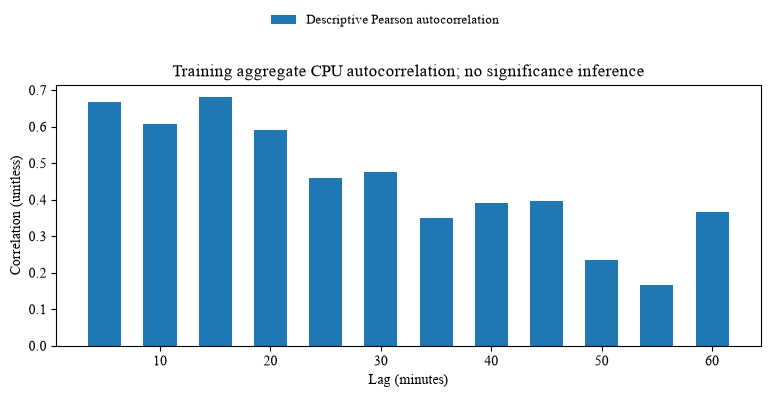

In [10]:
def plot_autocorrelation(acf: pd.DataFrame) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(acf.lag_minutes, acf.autocorrelation, width=3, label="Descriptive Pearson autocorrelation")
    ax.axhline(0, color="black", linewidth=.7)
    ax.set(xlabel="Lag (minutes)", ylabel="Correlation (unitless)", title="Training aggregate CPU autocorrelation; no significance inference")
    return fig

fig = plot_autocorrelation(*computed['plot_inputs']['autocorrelation'])
save_figure(fig, FIGURES / 'autocorrelation.png')
computed['figures']['autocorrelation'] = fig
FigureCanvasAgg(fig)
display(fig)

## 5. Segment Differences
**Observation -> explanation -> implication:** Interactive VMs have higher mean CPU and a larger high-utilization share than delay-insensitive VMs. Workload mix is a plausible explanation, not a proven causal effect. Monitor segments and individual high-CPU VMs alongside the fleet mean. Core and memory buckets are categorical labels, not precise capacities; very small groups do not support broad claims. This is segment analysis, not separately validated segment forecasting.

In [11]:
show_table(tables['segment_summary'])

,dimension,segment,vm_count,mean_cpu_pct,share_readings_ge80,share_readings_ge95,share_vm_mean_ge80
0,vm_category,Delay-insensitive,6180,8.25727,0.00892,0.00424,0.00615
1,vm_category,Interactive,3091,11.50515,0.01912,0.00777,0.01521
2,vm_category,Unknown,729,10.35469,0.01778,0.00879,0.01920
3,virtual_core_bucket,2,7534,9.76416,0.01452,0.00638,0.01141
4,virtual_core_bucket,24,62,11.42883,0.00000,0.00000,0.00000
5,virtual_core_bucket,4,1908,7.91872,0.00890,0.00437,0.00681
6,virtual_core_bucket,8,486,9.65840,0.00165,0.00045,0.00000
7,virtual_core_bucket,>24,10,6.61947,0.00000,0.00000,0.00000
8,memory_gb_bucket,2,3904,8.80225,0.00604,0.00310,0.00512
9,memory_gb_bucket,32,1383,7.81402,0.00212,0.00024,0.00217


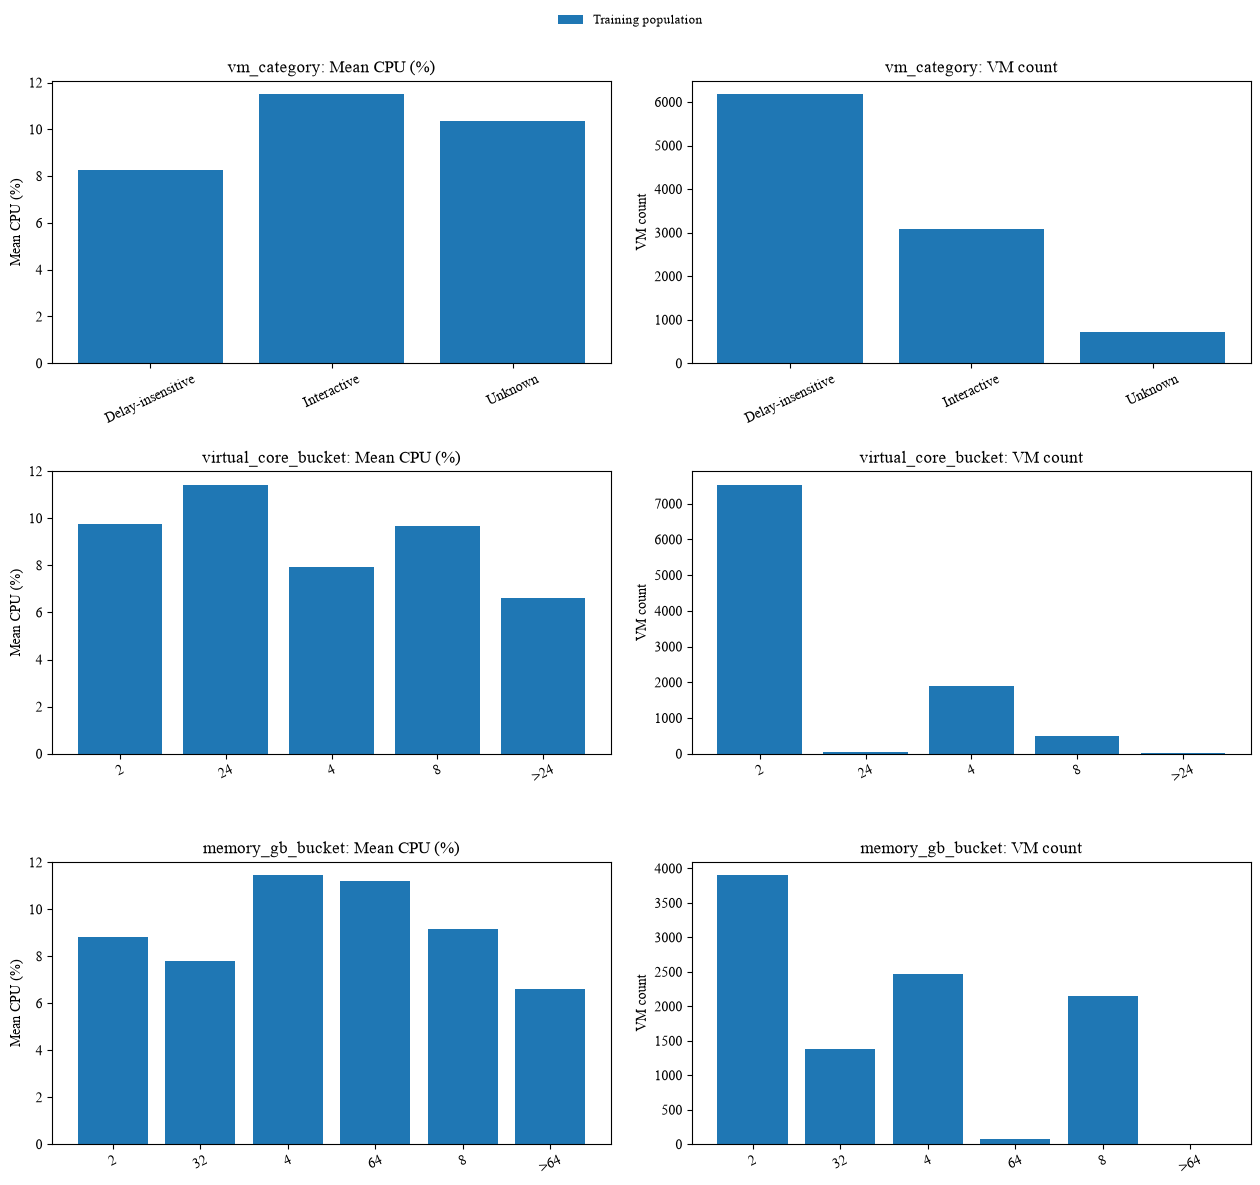

In [12]:
def plot_segments(segment: pd.DataFrame, dimensions: list[str]) -> Figure:
    fig, axes = plt.subplots(len(dimensions), 2, figsize=(13, 4 * len(dimensions)), squeeze=False)
    for row, column in enumerate(dimensions):
        group = segment[segment.dimension == column]
        for ax, metric, unit in ((axes[row, 0], "mean_cpu_pct", "Mean CPU (%)"),
                                 (axes[row, 1], "vm_count", "VM count")):
            ax.bar(group.segment, group[metric], label="Training population")
            ax.set(ylabel=unit, title=f"{column}: {unit}")
            ax.tick_params(axis="x", rotation=25)
    return fig

fig = plot_segments(*computed['plot_inputs']['segments'])
save_figure(fig, FIGURES / 'segments.png')
computed['figures']['segments'] = fig
FigureCanvasAgg(fig)
display(fig)

## 6. Model Comparison and Forecast Failures
**Observation -> explanation -> implication:** Persistence wins pooled CPU MAE; all count candidates have zero error. Smoothing lags the changing local level, and added trend did not improve MAE/RMSE. Retain the baseline instead of claiming a more complex model is better.

CPU errors are percentage points; count errors are VMs. Signed error is prediction minus actual. Peak cases use actual >= the origin's past-only q90 threshold; all 20 qualifying CPU peak cases occur at origin 50, so peak evidence is limited. Origin 50 underpredicts the rise while later origins overpredict the decline. Larger late-horizon errors support cautious refresh policies, not a confidently estimated error-growth law.

In [13]:
show_table(tables['model_comparison'])
show_table(tables['origin_metrics'])
show_table(tables['horizon_errors'])

,target,model,MAE,RMSE,bias,peak_MAE,relative_improvement,training_mean,normalized_MAE,normalized_MAE_pct,selected
0,active_vm_count,persistence,0.00000,0.00000,0.00000,0.00000,N/A,10000.00000,0.00000,0.00000,True
1,active_vm_count,mean_6,0.00000,0.00000,0.00000,0.00000,N/A,10000.00000,0.00000,0.00000,False
2,active_vm_count,mean_12,0.00000,0.00000,0.00000,0.00000,N/A,10000.00000,0.00000,0.00000,False
3,active_vm_count,mean_24,0.00000,0.00000,0.00000,0.00000,N/A,10000.00000,0.00000,0.00000,False
4,active_vm_count,ses_0.2,0.00000,0.00000,0.00000,0.00000,N/A,10000.00000,0.00000,0.00000,False
5,active_vm_count,ses_0.5,0.00000,0.00000,0.00000,0.00000,N/A,10000.00000,0.00000,0.00000,False
6,active_vm_count,damped_trend,0.00000,0.00000,0.00000,0.00000,N/A,10000.00000,0.00000,0.00000,False
7,aggregate_cpu_utilization,persistence,0.23531,0.27463,0.05864,0.30619,0.00000,9.41409,0.02500,2.49955,True
8,aggregate_cpu_utilization,mean_6,0.27141,0.31406,0.06048,0.36421,-0.15341,9.41409,0.02883,2.88300,False
9,aggregate_cpu_utilization,mean_12,0.28113,0.32991,0.06111,0.37349,-0.19471,9.41409,0.02986,2.98623,False


,target,model,origin,MAE,RMSE,bias,max_absolute_error,max_overprediction,max_underprediction,peak_threshold,peak_n,peak_MAE,peak_bias,first6_MAE,last6_MAE
0,active_vm_count,persistence,50,0.00000,0.00000,0.00000,0.00000,0.00000,-0.00000,10000.00000,24,0.00000,0.00000,0.00000,0.00000
1,active_vm_count,persistence,70,0.00000,0.00000,0.00000,0.00000,0.00000,-0.00000,10000.00000,24,0.00000,0.00000,0.00000,0.00000
2,active_vm_count,persistence,86,0.00000,0.00000,0.00000,0.00000,0.00000,-0.00000,10000.00000,24,0.00000,0.00000,0.00000,0.00000
3,aggregate_cpu_utilization,persistence,50,0.26809,0.30279,-0.24674,0.48582,0.17298,0.48582,9.52016,20,0.30619,-0.30619,0.20201,0.18398
4,aggregate_cpu_utilization,persistence,70,0.30541,0.33286,0.30541,0.54677,0.54677,0.00000,9.80379,0,N/A,N/A,0.20240,0.38732
5,aggregate_cpu_utilization,persistence,86,0.13243,0.15423,0.11725,0.25514,0.25514,0.07581,9.78149,0,N/A,N/A,0.13734,0.17589


,target,model,horizon,MAE,bias,n
0,active_vm_count,persistence,1,0.00000,0.00000,3
1,active_vm_count,persistence,2,0.00000,0.00000,3
2,active_vm_count,persistence,3,0.00000,0.00000,3
3,active_vm_count,persistence,4,0.00000,0.00000,3
4,active_vm_count,persistence,5,0.00000,0.00000,3
5,active_vm_count,persistence,6,0.00000,0.00000,3
6,active_vm_count,persistence,7,0.00000,0.00000,3
7,active_vm_count,persistence,8,0.00000,0.00000,3
8,active_vm_count,persistence,9,0.00000,0.00000,3
9,active_vm_count,persistence,10,0.00000,0.00000,3


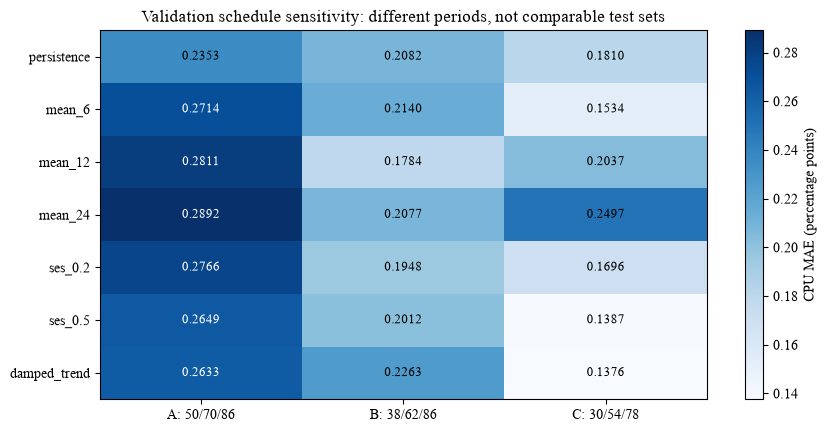

In [14]:
def plot_validation_schedules(sensitivity: pd.DataFrame, comparison: pd.DataFrame) -> Figure:
    matrix = sensitivity[sensitivity.target == "aggregate_cpu_utilization"].pivot(
        index="model", columns="schedule", values="MAE").reindex(
            index=comparison[comparison.target == "aggregate_cpu_utilization"].model,
            columns=["original", "alternative_a", "alternative_b"])
    fig, ax = plt.subplots(figsize=(9, 4.5))
    image = ax.imshow(matrix.to_numpy(), cmap="Blues", aspect="auto")
    ax.set_xticks(range(3), ["A: 50/70/86", "B: 38/62/86", "C: 30/54/78"])
    ax.set_yticks(range(len(matrix)), matrix.index)
    for row in range(len(matrix)):
        for column in range(3):
            ax.text(column, row, f"{matrix.iloc[row, column]:.4f}", ha="center", va="center",
                    color="white" if matrix.iloc[row, column] > .25 else "black", fontsize=9)
    fig.colorbar(image, ax=ax, label="CPU MAE (percentage points)")
    ax.set_title("Validation schedule sensitivity: different periods, not comparable test sets")
    return fig

fig = plot_validation_schedules(*computed['plot_inputs']['validation_schedules'])
save_figure(fig, FIGURES / 'validation_schedules.png')
computed['figures']['validation_schedules'] = fig
FigureCanvasAgg(fig)
display(fig)

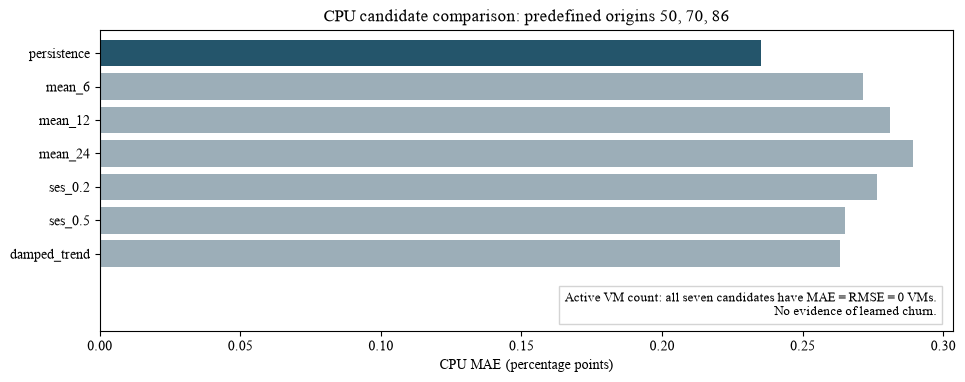

In [15]:
def plot_model_comparison(comparison: pd.DataFrame) -> Figure:
    fig, ax = plt.subplots(figsize=(10, 4))
    group = comparison[comparison.target == "aggregate_cpu_utilization"]
    ax.barh(group.model, group.MAE, color=["#24556b" if selected else "#9caeb8" for selected in group.selected])
    ax.invert_yaxis()
    ax.set_ylim(len(group) + 1.3, -.7)
    ax.set(xlabel="CPU MAE (percentage points)", title="CPU candidate comparison: predefined origins 50, 70, 86")
    ax.text(.98, .04, "Active VM count: all seven candidates have MAE = RMSE = 0 VMs.\nNo evidence of learned churn.",
            ha="right", va="bottom", transform=ax.transAxes, fontsize=9,
            bbox={"facecolor": "white", "alpha": .9, "edgecolor": "#d0d0d0"})
    return fig

fig = plot_model_comparison(*computed['plot_inputs']['model_comparison'])
save_figure(fig, FIGURES / 'model_comparison.png')
computed['figures']['model_comparison'] = fig
FigureCanvasAgg(fig)
display(fig)

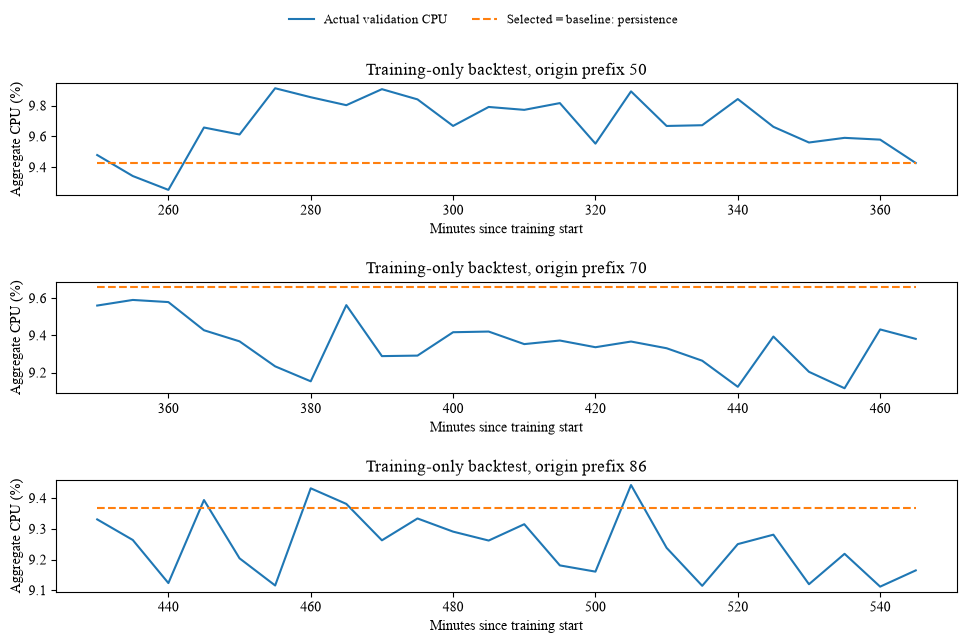

In [16]:
def plot_backtest_cpu(bt: pd.DataFrame, selection: dict[str, Any], start_timestamp: int) -> Figure:
    cpu_bt = bt[bt.target == "aggregate_cpu_utilization"]
    fig, axes = plt.subplots(len(selection["origins"]), 1, figsize=(10, 6.5), squeeze=False)
    cpu_choice = selection["targets"]["aggregate_cpu_utilization"]
    for ax, origin in zip(axes[:, 0], selection["origins"]):
        group = cpu_bt[cpu_bt.origin == origin]
        actual = group[group.model == cpu_choice["model"]]
        x = (actual.timestamp - start_timestamp) / 60
        ax.plot(x, actual.actual, label="Actual validation CPU")
        shared = cpu_choice["model"] == cpu_choice["best_baseline"]
        label = "Selected = baseline: persistence" if shared else f"Selected: {cpu_choice['model']}"
        ax.plot(x, actual.prediction, label=label, linestyle="--")
        if not shared:
            baseline = group[group.model == cpu_choice["best_baseline"]]
            ax.plot(x, baseline.prediction, linestyle=":", label=f"Baseline: {cpu_choice['best_baseline']}")
        ax.set(xlabel="Minutes since training start", ylabel="Aggregate CPU (%)",
               title=f"Training-only backtest, origin prefix {origin}")
    return fig

fig = plot_backtest_cpu(*computed['plot_inputs']['backtest_cpu'])
save_figure(fig, FIGURES / 'backtest_cpu.png')
computed['figures']['backtest_cpu'] = fig
FigureCanvasAgg(fig)
display(fig)

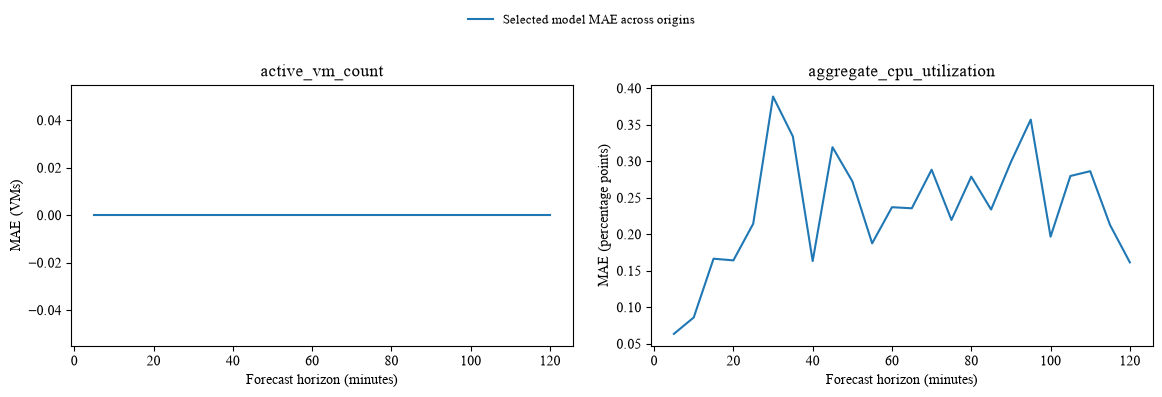

In [17]:
def plot_horizon_errors(horizon: pd.DataFrame) -> Figure:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, target in zip(axes, TARGETS):
        group = horizon[horizon.target == target]
        ax.plot(group.horizon * 5, group.MAE, label="Selected model MAE across origins")
        ax.set(xlabel="Forecast horizon (minutes)", ylabel="MAE (VMs)" if target == "active_vm_count" else "MAE (percentage points)", title=target)
    return fig

fig = plot_horizon_errors(*computed['plot_inputs']['horizon_errors'])
save_figure(fig, FIGURES / 'horizon_errors.png')
computed['figures']['horizon_errors'] = fig
FigureCanvasAgg(fig)
display(fig)

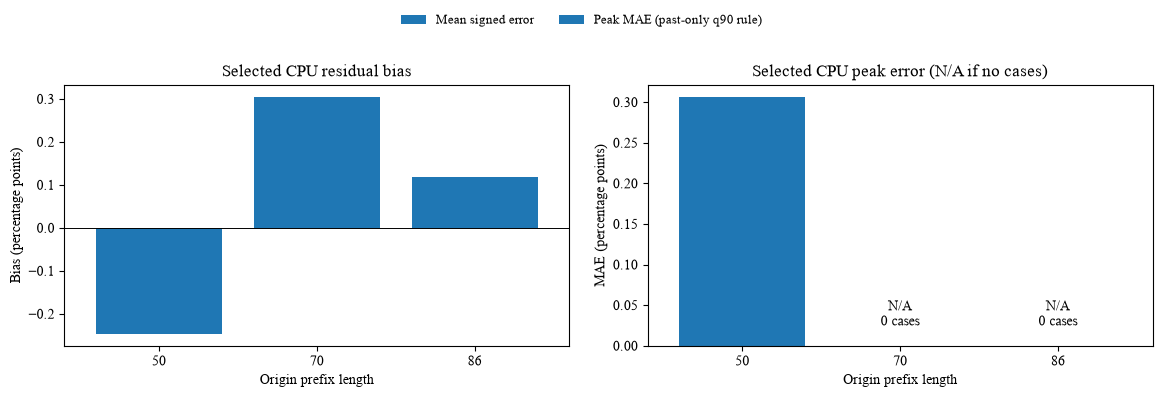

In [18]:
def plot_residual_bias_peak_errors(origin_metrics: pd.DataFrame) -> Figure:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    metrics = origin_metrics[origin_metrics.target == "aggregate_cpu_utilization"]
    positions = np.arange(len(metrics))
    axes[0].bar(positions, metrics.bias, label="Mean signed error")
    axes[0].axhline(0, color="black", linewidth=.7)
    axes[0].set(xlabel="Origin prefix length", ylabel="Bias (percentage points)", title="Selected CPU residual bias")
    axes[1].bar(positions, metrics.peak_MAE, label="Peak MAE (past-only q90 rule)")
    for position, row in zip(positions, metrics.itertuples()):
        if row.peak_n == 0:
            axes[1].text(position, 0.02, "N/A\n0 cases", ha="center", va="bottom")
    axes[1].set(xlabel="Origin prefix length", ylabel="MAE (percentage points)", title="Selected CPU peak error (N/A if no cases)")
    for ax in axes:
        ax.set_xticks(positions, metrics.origin.astype(str))
        ax.set_xlim(-.6, len(metrics) - .4)
    return fig

fig = plot_residual_bias_peak_errors(*computed['plot_inputs']['residual_bias_peak_errors'])
save_figure(fig, FIGURES / 'residual_bias_peak_errors.png')
computed['figures']['residual_bias_peak_errors'] = fig
FigureCanvasAgg(fig)
display(fig)

## 7. Infrastructure Recommendation and Limitations
Use the forecast as a monitoring reference, not a direct core/server allocation. The empirical q95 underprediction is about 0.4212 percentage points; the observed maximum is about 0.4858. A proposed **0.50-point buffer** rounds that observed maximum upward. Compare `min(100, forecast + 0.50)` with an operator-configured threshold and request review when it crosses. This is an illustrative rule, not a calibrated 95% bound.

A larger buffer reduces missed rises but increases false alerts and potential overprovisioning. Monitor segment-level high-load shares. Fall back to live monitoring/manual review on delayed telemetry, coverage loss, mix shifts, or errors beyond the observed buffer. Never scale down solely on the aggregate mean.

Overlapping windows, winner-selection optimism, short history, survivor selection, and missing exact capacities prevent claims of SLA protection, absolute resource savings, general fleet predictability, or validated autonomous scaling. Obtain longer representative history and independent error-calibration data next.

In [19]:
error_summary = summary['selected_validation']
show_table(pd.DataFrame([{key: error_summary[key] for key in ['underprediction_q90_pp', 'underprediction_q95_pp', 'underprediction_max_pp', 'first6_MAE_pp', 'last6_MAE_pp']}]))
print('Illustrative buffer: 0.50 percentage points; no guaranteed future coverage.')
show_table(tables['capacity_schedule'])

,underprediction_q90_pp,underprediction_q95_pp,underprediction_max_pp,first6_MAE_pp,last6_MAE_pp
0,0.37493,0.42116,0.48582,0.18059,0.24906


Illustrative buffer: 0.50 percentage points; no guaranteed future coverage.


,timestamp,horizon,minutes_ahead,point_forecast,validation_origins,raw_buffer_p90_pp,raw_buffer_p95_pp,buffer_p90_pp,buffer_p95_pp,reference_p90_pct,reference_p95_pct
0,33000,1,5,9.16456,3,0.04229,0.04758,0.04229,0.04758,9.20685,9.21213
1,33300,2,10,9.16456,3,0.00000,0.00000,0.04229,0.04758,9.20685,9.21213
2,33600,3,15,9.16456,3,0.00000,0.00000,0.04229,0.04758,9.20685,9.21213
3,33900,4,20,9.16456,3,0.19037,0.21080,0.19037,0.21080,9.35492,9.37536
4,34200,5,25,9.16456,3,0.14872,0.16731,0.19037,0.21080,9.35492,9.37536
5,34500,6,30,9.16456,3,0.38866,0.43724,0.38866,0.43724,9.55321,9.60180
6,34800,7,35,9.16456,3,0.35514,0.39139,0.38866,0.43724,9.55321,9.60180
7,35100,8,40,9.16456,3,0.30373,0.33991,0.38866,0.43724,9.55321,9.60180
8,35400,9,45,9.16456,3,0.38387,0.43185,0.38866,0.43724,9.55321,9.60180
9,35700,10,50,9.16456,3,0.33090,0.37226,0.38866,0.43724,9.55321,9.60180


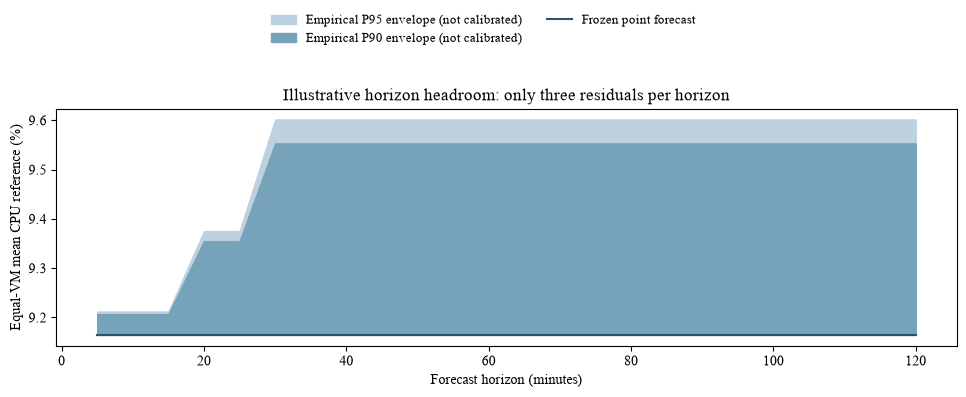

In [20]:
def plot_horizon_headroom(capacity_schedule: pd.DataFrame) -> Figure:
    fig, ax = plt.subplots(figsize=(10, 4))
    for percentile, color in (("p95", "#bdd2de"), ("p90", "#76a2ba")):
        ax.fill_between(capacity_schedule.minutes_ahead, capacity_schedule.point_forecast,
                        capacity_schedule[f"reference_{percentile}_pct"], color=color,
                        label=f"Empirical {percentile.upper()} envelope (not calibrated)")
    ax.plot(capacity_schedule.minutes_ahead, capacity_schedule.point_forecast, color="#24556b", label="Frozen point forecast")
    ax.set(xlabel="Forecast horizon (minutes)", ylabel="Equal-VM mean CPU reference (%)",
           title="Illustrative horizon headroom: only three residuals per horizon")
    return fig

fig = plot_horizon_headroom(*computed['plot_inputs']['horizon_headroom'])
save_figure(fig, FIGURES / 'horizon_headroom.png')
computed['figures']['horizon_headroom'] = fig
FigureCanvasAgg(fig)
display(fig)

## 8. Generate and Verify the Submission
The table below contains forecasts, not observed holdout labels. Invoke the same documented CLI, verify all timestamps/schema/ranges, and compare to the frozen forecast. The separate perturbation evidence checks that extreme/missing holdout labels do not change predictions, selection, or backtests.

In [21]:
result = subprocess.run([sys.executable, '-m', 'atomity_forecasting.predict', '--data', str(DATA), '--output', str(ROOT / 'predictions.csv')], check=True, capture_output=True, text=True)
saved = predictions.copy()
assert saved.columns.tolist() == ['timestamp', 'active_vm_count', 'aggregate_cpu_utilization']
assert len(saved) == 24 and not saved.timestamp.duplicated().any()
np.testing.assert_array_equal(saved.timestamp.to_numpy(), forecast_timestamps.to_numpy())
assert np.isfinite(saved.to_numpy()).all()
assert saved.active_vm_count.ge(0).all()
assert saved.aggregate_cpu_utilization.between(0, 100).all()
pd.testing.assert_frame_equal(saved, predictions, check_exact=False, rtol=1e-14)
isolation = summaries['holdout_isolation_check']
assert isolation['passed']
show_table(pd.DataFrame(isolation['checks']))
show_table(saved)
print('Prediction contract and holdout-isolation checks passed.')

,perturbation,changed_rows,targets,predictions_exactly_equal,selection_exactly_equal,backtests_exactly_equal
0,extreme_finite,24,"['active_vm_count', 'aggregate_cpu_utilization']",True,True,True
1,all_nan,24,"['active_vm_count', 'aggregate_cpu_utilization']",True,True,True


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.16456
1,33300,10000,9.16456
2,33600,10000,9.16456
3,33900,10000,9.16456
4,34200,10000,9.16456
5,34500,10000,9.16456
6,34800,10000,9.16456
7,35100,10000,9.16456
8,35400,10000,9.16456
9,35700,10000,9.16456


Prediction contract and holdout-isolation checks passed.


## 9. Automated Tests and Final Report
Tests cover targets, duplicates, invalid/missing readings, chronological splitting, horizon, finite/range/schema checks, reproducibility, holdout independence, and a tiny three-VM CLI smoke dataset. The PDF renderer creates six main-report pages plus a figure appendix. No employer submission or email is performed.

In [22]:
result = subprocess.run([sys.executable, '-m', 'pytest', '-q'], cwd=ROOT, check=True, capture_output=True, text=True)
print(result.stdout)
result = subprocess.run([sys.executable, str(ROOT / 'scripts/render_report.py')], cwd=ROOT, check=True, capture_output=True, text=True)
print(result.stdout)
display(Markdown('Review [the report](../reports/final_report.md), [PDF](../reports/final_report.pdf), and [verification handoff](../reports/verification.md).'))

........................................................................ [ 47%]
........................................................................ [ 94%]
........                                                                 [100%]
152 passed in 8.00s



Rendered /Users/hisbaan/Projects/TASK/reports/final_report.pdf: 6 core pages + 6 appendix pages = 12 total pages



Review [the report](../reports/final_report.md), [PDF](../reports/final_report.pdf), and [verification handoff](../reports/verification.md).